## Notebook 05 — Ward Clustering & Mobility Segmentation

**Project roadmap:** Phase 6 — Unsupervised Learning & Anomaly Detection (clustering component).

### 5.1 Clustering Feasibility & Candidate Feature Assessment

**Objective:** Evaluate the Phase 3 ward-level dataset and identify suitable features for grouping Bengaluru wards by similar mobility characteristics. This extends NammaFlow’s analysis from estimating historical booking conversion to understanding broader ward profiles.

**Why clustering?** Wards differ in demand, driver activity, and ride conversion. Clustering examines these characteristics together to identify patterns that can support dashboard exploration and further operational investigation.

**Key questions:**

1. Which features provide meaningful and distinct information about ward mobility?
2. How should missing values, extreme observations, and differences in feature scale be handled?
3. Are demand and supply measurements sufficiently comparable to combine?
4. Do the resulting groups remain reasonably stable and have clear, data-supported interpretations?

**Important limitation:** Clusters describe patterns in the available aggregate data. They do not establish causes, prove driver shortages, or demonstrate that an operational intervention will improve outcomes.

We will begin by auditing feature distributions, data quality, and redundancy before selecting clustering inputs or choosing the number of clusters.

In [ ]:
from pathlib import Path
import subprocess
import pandas as pd

repo = Path("/content/NammaFlow")

if not repo.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Narasimhan15/NammaFlow.git",
            str(repo),
        ],
        check=True,
    )

ward_df = pd.read_csv(
    repo / "data/features/ward_intelligence.csv"
)

assert ward_df["ward_num"].is_unique, "Duplicate ward IDs found"

feature_audit = pd.DataFrame({
    "dtype": ward_df.dtypes.astype(str),
    "missing": ward_df.isna().sum(),
    "unique_values": ward_df.nunique(),
})

print("Dataset shape:", ward_df.shape)
print("\nFEATURE AUDIT")
print(feature_audit.to_string())

Dataset shape: (244, 65)

FEATURE AUDIT
                                       dtype  missing  unique_values
ward_num                              object        0            244
ward_searches                          int64        0            140
ward_searches_got_e                    int64        0            141
ward_q_requests                        int64        0            116
ward_q_received                        int64        0             87
ward_search_to_e_rate                float64        0              7
ward_e_to_q_request_rate             float64        0            193
ward_q_accept_rate                   float64        1            170
ward_search_to_q_request_rate        float64        0            194
ward_search_to_q_received_rate       float64        0            188
ward_q_supply_gap                      int64        0             83
ward_q_supply_gap_rate               float64        1            170
ward_search_to_q_received_gap          int64        0          

In [ ]:
import numpy as np
import pandas as pd

candidate_features = [
    "ward_searches",
    "active_drvr_auto_cab",
    "ward_search_to_booking_rate",
    "ward_booking_completion_rate",
    "ward_driver_utilization_rate",
]

candidate_df = ward_df[candidate_features].copy()

print("CANDIDATE FEATURE DISTRIBUTIONS")
display(
    candidate_df.describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    ).T
)

print("\nMISSING AND NON-FINITE VALUES")
display(pd.DataFrame({
    "missing": candidate_df.isna().sum(),
    "infinite": np.isinf(candidate_df).sum(),
}))

print("\nSPEARMAN CORRELATIONS")
display(candidate_df.corr(method="spearman").round(3))

print("\nHIGHEST SEARCH VOLUMES")
display(
    ward_df[["ward_num"] + candidate_features]
    .nlargest(5, "ward_searches")
)

print("\nHIGHEST DRIVER COUNTS")
display(
    ward_df[["ward_num"] + candidate_features]
    .nlargest(5, "active_drvr_auto_cab")
)

CANDIDATE FEATURE DISTRIBUTIONS


,count,mean,std,min,1%,25%,50%,75%,99%,max
ward_searches,244.0,148.000000,424.702820,2.0,4.000000,26.750000,48.500000,117.750000,1635.350000,4862.00
active_drvr_auto_cab,244.0,200.659836,555.865724,1.0,9.720000,64.000000,116.000000,211.250000,799.310000,8519.00
ward_search_to_booking_rate,244.0,0.338872,0.113377,0.0,0.045263,0.271882,0.333333,0.405240,0.622850,0.76
ward_booking_completion_rate,241.0,0.535065,0.185113,0.0,0.000000,0.435484,0.515625,0.625000,1.000000,1.00
ward_driver_utilization_rate,244.0,0.156811,0.092367,0.0,0.000000,0.084746,0.139410,0.210165,0.402885,0.45



MISSING AND NON-FINITE VALUES


,missing,infinite
ward_searches,0,0
active_drvr_auto_cab,0,0
ward_search_to_booking_rate,0,0
ward_booking_completion_rate,3,0
ward_driver_utilization_rate,0,0



SPEARMAN CORRELATIONS


,ward_searches,active_drvr_auto_cab,ward_search_to_booking_rate,ward_booking_completion_rate,ward_driver_utilization_rate
ward_searches,1.000,0.732,-0.113,-0.215,0.296
active_drvr_auto_cab,0.732,1.000,-0.019,-0.088,-0.010
ward_search_to_booking_rate,-0.113,-0.019,1.000,0.088,0.021
ward_booking_completion_rate,-0.215,-0.088,0.088,1.000,-0.064
ward_driver_utilization_rate,0.296,-0.010,0.021,-0.064,1.000



HIGHEST SEARCH VOLUMES


,ward_num,ward_searches,active_drvr_auto_cab,ward_search_to_booking_rate,ward_booking_completion_rate,ward_driver_utilization_rate
91,b_181,4862,686,0.114356,0.388489,0.300292
243,w_0,3460,8519,0.224277,0.476804,0.045076
97,b_187,1874,382,0.234792,0.320455,0.164921
38,b_133,1319,502,0.294920,0.401028,0.147410
87,b_178,1119,340,0.249330,0.462366,0.138235



HIGHEST DRIVER COUNTS


,ward_num,ward_searches,active_drvr_auto_cab,ward_search_to_booking_rate,ward_booking_completion_rate,ward_driver_utilization_rate
243,w_0,3460,8519,0.224277,0.476804,0.045076
17,b_114,355,892,0.335211,0.478992,0.164798
19,b_116,472,835,0.404661,0.445026,0.093413
18,b_115,168,752,0.398810,0.462687,0.093085
91,b_181,4862,686,0.114356,0.388489,0.300292


**5.1 — Candidate Feature Diagnostics: Findings**

**Findings:**
- Search and active-driver counts have strongly uneven distributions,
  with maxima substantially above their medians.
- Booking completion rate is missing for three wards.
- No infinite values were found in the five candidate features.
- Search volume and active-driver count have a Spearman correlation
  of 0.732, indicating substantial overlap in their rankings.
- The remaining candidate-feature correlations are comparatively weak.
- Record w_0 has an unusually large driver count and requires source
  interpretation before inclusion in geographic ward clustering.

**Next step:** Verify rate denominators, investigate w_0, and review
demand–supply source compatibility before finalising preprocessing
and clustering features.

In [ ]:
# 5.2.1 — Missing-Rate and Special-Ward Inspection

review_columns = [
    "ward_num",
    "ward_searches",
    "ward_bookings",
    "ward_completed_rides",
    "ward_booking_completion_rate",
    "active_drvr_auto_cab",
    "ward_driver_utilization_rate",
]

print("WARDS WITH MISSING BOOKING COMPLETION RATE")
display(
    ward_df.loc[
        ward_df["ward_booking_completion_rate"].isna(),
        review_columns,
    ]
)

print("\nSPECIAL RECORD: w_0")
display(
    ward_df.loc[
        ward_df["ward_num"].eq("w_0"),
        review_columns,
    ]
)

print("\nWARD IDENTIFIER PREFIX COUNTS")
print(
    ward_df["ward_num"]
    .astype(str)
    .str.extract(r"^([^_]+)", expand=False)
    .value_counts()
)

WARDS WITH MISSING BOOKING COMPLETION RATE


,ward_num,ward_searches,ward_bookings,ward_completed_rides,ward_booking_completion_rate,active_drvr_auto_cab,ward_driver_utilization_rate
76,b_168,13,0,0,NaN,41,0.146341
162,b_26,8,0,0,NaN,39,0.025641
182,b_44,2,0,0,NaN,48,0.041667



SPECIAL RECORD: w_0


,ward_num,ward_searches,ward_bookings,ward_completed_rides,ward_booking_completion_rate,active_drvr_auto_cab,ward_driver_utilization_rate
243,w_0,3460,776,370,0.476804,8519,0.045076



WARD IDENTIFIER PREFIX COUNTS
ward_num
b    243
w      1
Name: count, dtype: int64


**5.2.1 — Missing-Rate and Special-Record Findings**

- Three wards have undefined booking-completion rates because both
  bookings and completed rides are zero.
- These missing rates represent an undefined denominator, not a
  measured completion rate of zero.
- The dataset contains 243 b_-prefixed records and one w_0 record.
- The geographic meaning of w_0 remains unverified. Its unusually
  large driver count warrants separate review.

**Decision:** Preserve the original data. Do not impute undefined rates
or exclude w_0 solely on the basis of its identifier or magnitude.

Verifying the feature formulas and source notes before deciding how to handle these records

In [ ]:
# 5.2.2 — Feature Definition and Source-Note Review

import json
from pathlib import Path

phase3_path = Path(
    "/content/NammaFlow/notebooks/03_feature_engineering.ipynb"
)

with phase3_path.open(encoding="utf-8") as f:
    phase3_nb = json.load(f)

terms = [
    "ward_booking_completion_rate",
    "ward_driver_utilization_rate",
    "w_0",
]

for term in terms:
    print(f"\n{'=' * 60}\nSEARCH TERM: {term}")

    for cell_number, cell in enumerate(phase3_nb["cells"], start=1):
        source = "".join(cell.get("source", []))
        lines = source.splitlines()

        matching_lines = [
            i for i, line in enumerate(lines) if term in line
        ]

        if matching_lines:
            print(f"\nCell {cell_number} ({cell['cell_type']}):")
            shown = set()

            for i in matching_lines:
                for j in range(max(0, i - 3), min(len(lines), i + 5)):
                    if j not in shown:
                        print(lines[j])
                        shown.add(j)


SEARCH TERM: ward_booking_completion_rate

Cell 73 (code):
    ward_operations_summary["ward_rides"]
)

ward_operations_summary["ward_booking_completion_rate"] = safe_divide(
    ward_operations_summary["ward_completed_rides"],
    ward_operations_summary["ward_bookings"]
)


Cell 74 (code):
operation_summary_rate_cols = [
    "ward_booking_to_ride_rate",
    "ward_ride_completion_rate",
    "ward_booking_completion_rate",
    "ward_cancel_per_booking"
]

for col in operation_summary_rate_cols:

SEARCH TERM: ward_driver_utilization_rate

Cell 77 (code):
# Ward-level driver utilization
# ----------------------------------------------

ward_supply_summary["ward_driver_utilization_rate"] = safe_divide(
    ward_supply_summary["onride_drvr_auto_cab"],
    ward_supply_summary["active_drvr_auto_cab"]
)


Cell 78 (code):
print("\nDriver share consistency:")

ward_supply_summary["ward_driver_share_sum"] = (
    ward_supply_summary["ward_driver_utilization_rate"]
    + ward_supply_summary["war

**5.2.2 — Feature Definition Review: Findings**

**Verified formulas:**
- Booking completion rate = completed rides / bookings.
- Driver utilization rate = on-ride drivers / active drivers.

**Interpretation:**
- Booking completion rate remains undefined when bookings are zero.
- Driver utilization represents the recorded share of active drivers
  on a ride; it does not establish full-day utilization.
- Phase 3 documentation does not establish the geographic meaning of w_0.
- Formula verification alone does not establish temporal compatibility
  between demand and supply sources.

**Next step:** Review source coverage and aggregation before combining
demand and supply features in the primary clustering model.

In [ ]:
# 5.2.3 — Source Coverage and Aggregation Review

import json
from pathlib import Path

terms = [
    "snapshot",
    "timestamp",
    "same period",
    "different period",
    "alignment",
    "time coverage",
    "groupby",
]

repo = Path("/content/NammaFlow")

for filename in [
    "02_exploratory_data_analysis.ipynb",
    "03_feature_engineering.ipynb",
]:
    with (repo / "notebooks" / filename).open(
        encoding="utf-8"
    ) as f:
        notebook = json.load(f)

    print(f"\n{'=' * 60}\n{filename}")

    for number, cell in enumerate(notebook["cells"], start=1):
        source = "".join(cell.get("source", []))
        lower = source.lower()

        relevant = (
            cell["cell_type"] == "markdown"
            and any(term in lower for term in terms[:-1])
        ) or (
            cell["cell_type"] == "code"
            and "groupby" in lower
            and any(
                term in lower
                for term in ["driver", "supply", "funnel"]
            )
        )

        if relevant:
            print(f"\nCell {number} ({cell['cell_type']}):")
            print(source)


02_exploratory_data_analysis.ipynb

Cell 46 (code):
hourly_funnel = (
    city_demand_hourly
    .groupby("hour", as_index=False)
    .agg(
        observed_days=("date", "nunique"),
        search_requests=("search_requests", "sum"),
        searches_with_e=("searches_with_e", "sum"),
        searches_for_q=("searches_for_q", "sum"),
        searches_with_q=("searches_with_q", "sum")
    )
)

hourly_funnel["e_stage_rate"] = (
    hourly_funnel["searches_with_e"]
    / hourly_funnel["search_requests"] * 100
)

hourly_funnel["q_request_rate"] = (
    hourly_funnel["searches_for_q"]
    / hourly_funnel["search_requests"] * 100
)

hourly_funnel["q_success_rate"] = (
    hourly_funnel["searches_with_q"]
    / hourly_funnel["searches_for_q"] * 100
)

hourly_funnel[
    [
        "hour",
        "observed_days",
        "search_requests",
        "e_stage_rate",
        "q_request_rate",
        "q_success_rate"
    ]
].round(2)

Cell 58 (code):
city_operations["date"] = pd.to_datetime(city

**5.2.3 — Source Review and Initial Clustering Scope**

**Findings:** Source aggregation and ward-key alignment are documented,
but temporal compatibility between demand and driver supply has not
been established. The geographic meaning of w_0 remains unresolved.

**Initial approach:** Build exploratory clusters using search volume,
search-to-booking conversion, and booking-completion rate. Driver-supply
features will be reserved for separate profiling pending compatibility
checks.

**Data handling:** Preserve the original dataset. Exclude the three
undefined completion-rate records from this initial fit and retain
them for separate reporting. Assess sensitivity to w_0 before choosing
the final clustering solution.

In [ ]:
# 5.3.1 — Prepare Initial Demand-and-Funnel Features

import numpy as np
import pandas as pd

initial_features = [
    "ward_searches",
    "ward_search_to_booking_rate",
    "ward_booking_completion_rate",
]

eligible = ward_df[initial_features].notna().all(axis=1)

clustering_excluded = ward_df.loc[
    ~eligible, ["ward_num"] + initial_features
].copy()

clustering_base = ward_df.loc[
    eligible, ["ward_num"] + initial_features
].copy()

assert clustering_base["ward_num"].is_unique
assert np.isfinite(
    clustering_base[initial_features].to_numpy()
).all()
assert clustering_base["ward_searches"].ge(0).all()

rate_columns = initial_features[1:]
assert clustering_base[rate_columns].ge(0).all().all()
assert clustering_base[rate_columns].le(1).all().all()

clustering_features = pd.DataFrame({
    "log_searches": np.log1p(clustering_base["ward_searches"]),
    "booking_conversion": clustering_base[
        "ward_search_to_booking_rate"
    ],
    "booking_completion": clustering_base[
        "ward_booking_completion_rate"
    ],
}, index=clustering_base.index)

print("Eligible records:", len(clustering_base))
print("Excluded records:", len(clustering_excluded))
display(clustering_excluded)

print("\nTRANSFORMED FEATURE SUMMARY")
display(clustering_features.describe().T.round(4))

print("\nSPEARMAN CORRELATIONS")
display(
    clustering_features.corr(method="spearman").round(3)
)

Eligible records: 241
Excluded records: 3


,ward_num,ward_searches,ward_search_to_booking_rate,ward_booking_completion_rate
76,b_168,13,0.0,NaN
162,b_26,8,0.0,NaN
182,b_44,2,0.0,NaN



TRANSFORMED FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
log_searches,241.0,4.0808,1.1924,1.3863,3.3322,3.9120,4.7958,8.4894
booking_conversion,241.0,0.3431,0.1075,0.1053,0.2727,0.3333,0.4070,0.7600
booking_completion,241.0,0.5351,0.1851,0.0000,0.4355,0.5156,0.6250,1.0000



SPEARMAN CORRELATIONS


,log_searches,booking_conversion,booking_completion
log_searches,1.000,-0.152,-0.215
booking_conversion,-0.152,1.000,0.088
booking_completion,-0.215,0.088,1.000


### 5.3.2 — Feature Scaling and Candidate Cluster Evaluation

**Objective:** Standardize the three selected features and compare
K-Means solutions containing 2–8 clusters.

**Why scaling?** Even after transforming search counts, the features
have different spreads. Standardization gives each feature equal
variance in the distance calculation.

**Evaluation:** Compare silhouette scores, inertia, and cluster sizes.
These diagnostics will guide further inspection; they will not
automatically determine the final number of clusters.

Low-volume rate reliability, sensitivity to w_0, and clustering
stability remain to be assessed.

In [ ]:
# 5.3.2 — Scale Features and Compare Candidate Cluster Counts

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_scaler = StandardScaler()

X_cluster = pd.DataFrame(
    cluster_scaler.fit_transform(clustering_features),
    columns=clustering_features.columns,
    index=clustering_features.index,
)

assert np.isfinite(X_cluster.to_numpy()).all()

candidate_models = {}
evaluation_rows = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42,
    )
    labels = model.fit_predict(X_cluster)
    sizes = np.bincount(labels, minlength=k)

    candidate_models[k] = model

    evaluation_rows.append({
        "k": k,
        "silhouette": silhouette_score(X_cluster, labels),
        "inertia": model.inertia_,
        "smallest_cluster": sizes.min(),
        "largest_cluster": sizes.max(),
        "cluster_sizes": sizes.tolist(),
    })

cluster_evaluation = pd.DataFrame(evaluation_rows)

print("SCALED FEATURE CHECK")
display(pd.DataFrame({
    "mean": X_cluster.mean(),
    "std_population": X_cluster.std(ddof=0),
}).round(4))

print("\nCANDIDATE CLUSTER EVALUATION")
display(cluster_evaluation.round(4))

SCALED FEATURE CHECK


,mean,std_population
log_searches,0.0,1.0
booking_conversion,-0.0,1.0
booking_completion,-0.0,1.0



CANDIDATE CLUSTER EVALUATION


,k,silhouette,inertia,smallest_cluster,largest_cluster,cluster_sizes
0,2,0.2655,520.9208,103,138,"[138, 103]"
1,3,0.2858,400.2934,46,128,"[128, 67, 46]"
2,4,0.3000,309.1374,46,71,"[71, 46, 69, 55]"
3,5,0.2820,259.4475,31,83,"[31, 43, 83, 49, 35]"
4,6,0.2756,227.8628,24,65,"[65, 39, 37, 32, 44, 24]"
5,7,0.2804,203.4170,12,61,"[61, 38, 47, 29, 20, 12, 34]"
6,8,0.2818,183.6002,12,52,"[38, 50, 20, 15, 52, 19, 35, 12]"


**5.3.2 — Candidate Cluster Evaluation: Findings**

- Standardization produced approximately zero means and unit variances.
- Among the tested solutions, k=4 has the highest silhouette score
  (0.3000), with cluster sizes of 71, 46, 69, and 55.
- The k=3 solution is a simpler alternative with a silhouette of 0.2858.
- Separation is limited; these results do not establish distinct
  natural categories.

**Next step:** Compare k=3 and k=4 for sensitivity to random
initialization before inspecting cluster profiles and sensitivity
to w_0.

In [ ]:
# 5.3.3 — Random-Initialization Stability

from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

stability_rows = []

for k in [3, 4]:
    label_sets = []

    for seed in range(10):
        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=seed,
        )
        label_sets.append(model.fit_predict(X_cluster))

    pairwise_ari = [
        adjusted_rand_score(a, b)
        for a, b in combinations(label_sets, 2)
    ]

    stability_rows.append({
        "k": k,
        "runs": len(label_sets),
        "mean_pairwise_ARI": np.mean(pairwise_ari),
        "minimum_pairwise_ARI": np.min(pairwise_ari),
    })

initialization_stability = pd.DataFrame(stability_rows)

print("RANDOM-INITIALIZATION STABILITY")
display(initialization_stability.round(4))

RANDOM-INITIALIZATION STABILITY


,k,runs,mean_pairwise_ARI,minimum_pairwise_ARI
0,3,10,0.9876,0.9734
1,4,10,1.0000,1.0000


### Clustering Approach — Purpose and Method

**Why clustering?** Group wards with similar search activity, booking
conversion, and booking completion to make mobility patterns easier
to compare and interpret.

**Technique:** K-Means clustering on three standardized numerical
features, with search volume log-transformed before scaling.

**Why K-Means?** It provides a simple, computationally efficient
baseline with cluster centres that can be interpreted through feature
profiles. Standardization prevents differences in feature spread
from dominating the distance calculation.

**Current evidence:** Among k=2–8, k=4 achieved the highest silhouette
score (0.3000). It also produced identical group membership across
10 random-seed runs (ARI=1.0000).

**Limitation:** K-Means favours compact groups and is sensitive to
feature choices and unusual observations. Initialization stability
does not prove that the clusters are natural or operationally useful.
Four clusters remains provisional pending further validation.

### 5.4.1 — Candidate Cluster Profiles

**Objective:** Compare the size, demand share, and typical conversion
rates of the k=3 and k=4 groups.

**Why this step?** A useful segmentation should have understandable
profiles as well as reasonable evaluation scores.

Cluster numbers are identifiers, not rankings. Names will be assigned
after reviewing profiles and completing sensitivity checks.

In [ ]:
# 5.4.1 — Compare Cluster Profiles in Original Units

import pandas as pd

candidate_profiles = {}
candidate_assignments = {}

assert clustering_base.index.equals(X_cluster.index)

for k in [3, 4]:
    profile_data = clustering_base.copy()
    profile_data["cluster"] = candidate_models[k].predict(X_cluster)

    # Add counts for pooled rates and denominator reliability checks.
    for column in ["ward_bookings", "ward_completed_rides"]:
        profile_data[column] = ward_df.loc[
            profile_data.index, column
        ]

    summary = (
        profile_data.groupby("cluster")
        .agg(
            record_count=("ward_num", "size"),
            total_searches=("ward_searches", "sum"),
            median_searches=("ward_searches", "median"),
            median_booking_conversion=(
                "ward_search_to_booking_rate", "median"
            ),
            median_booking_completion=(
                "ward_booking_completion_rate", "median"
            ),
            total_bookings=("ward_bookings", "sum"),
            total_completed=("ward_completed_rides", "sum"),
            records_below_30_searches=(
                "ward_searches", lambda x: (x < 30).sum()
            ),
            records_below_10_bookings=(
                "ward_bookings", lambda x: (x < 10).sum()
            ),
        )
    )

    summary["search_share_pct"] = (
        summary["total_searches"]
        / summary["total_searches"].sum() * 100
    )
    summary["pooled_booking_conversion_pct"] = (
        summary["total_bookings"] / summary["total_searches"] * 100
    )
    summary["pooled_booking_completion_pct"] = (
        summary["total_completed"] / summary["total_bookings"] * 100
    )

    summary["median_booking_conversion_pct"] = (
        summary.pop("median_booking_conversion") * 100
    )
    summary["median_booking_completion_pct"] = (
        summary.pop("median_booking_completion") * 100
    )

    candidate_profiles[k] = summary
    candidate_assignments[k] = profile_data

    print(f"\nK={k} — CLUSTER PROFILES")
    display(summary.round(2))

    print("w_0 assignment:")
    display(
        profile_data.loc[
            profile_data["ward_num"].eq("w_0"),
            ["ward_num", "cluster", "ward_searches"]
        ]
    )


K=3 — CLUSTER PROFILES


,record_count,total_searches,median_searches,total_bookings,total_completed,records_below_30_searches,records_below_10_bookings,search_share_pct,pooled_booking_conversion_pct,pooled_booking_completion_pct,median_booking_conversion_pct,median_booking_completion_pct
cluster,,,,,,,,,,,,
0,128,31829,101.5,8213,3771,12,20,88.20,25.80,45.92,30.16,46.82
1,67,2916,30.0,1347,727,33,18,8.08,46.19,53.97,45.45,53.33
2,46,1344,28.5,376,280,24,29,3.72,27.98,74.47,30.00,74.17


w_0 assignment:


,ward_num,cluster,ward_searches
243,w_0,0,3460



K=4 — CLUSTER PROFILES


,record_count,total_searches,median_searches,total_bookings,total_completed,records_below_30_searches,records_below_10_bookings,search_share_pct,pooled_booking_conversion_pct,pooled_booking_completion_pct,median_booking_conversion_pct,median_booking_completion_pct
cluster,,,,,,,,,,,,
0,71,29193,214.0,7514,3510,0,0,80.89,25.74,46.71,31.84,49.30
1,46,1473,32.0,420,308,21,26,4.08,28.51,73.33,30.00,74.17
2,69,2885,33.0,1309,700,31,16,7.99,45.37,53.48,44.62,53.33
3,55,2538,39.0,693,260,17,25,7.03,27.30,37.52,27.78,37.04


w_0 assignment:


,ward_num,cluster,ward_searches
243,w_0,0,3460


**5.4.1 — Candidate Cluster Profiles: Findings**

**Four-cluster solution:**
- Cluster 0: 71 records and 80.89% of eligible searches, with a
  median of 214 searches per record.
- Cluster 1: 46 records, with relatively high median booking
  completion (74.17%) and median booking conversion of 30.00%.
- Cluster 2: 69 records, with the highest median booking conversion
  (44.62%) and median booking completion of 53.33%.
- Cluster 3: 55 records, with the lowest median booking conversion
  (27.78%) and booking completion (37.04%).

**Comparison:** The three-cluster solution groups 128 records into
its largest segment. The four-cluster solution provides a more
detailed separation of volume and funnel-performance patterns.

**Reliability:** Clusters 1 and 3 contain 26 and 25 records,
respectively, with fewer than 10 bookings. Their completion rates
may be sensitive to small counts.

**Special record:** w_0 belongs to cluster 0 in both solutions.
Its influence will be assessed separately.

**Decision:** Retain k=4 as the leading candidate pending sensitivity
and sampling-stability checks. Cluster descriptions are provisional;
cluster numbers are identifiers, not rankings.

### 5.4.2 — Sensitivity to w_0

**Objective:** Assess whether the unresolved record w_0 materially
affects clustering of the remaining records.

**Method:** Remove w_0, refit the scaler and K-Means models, and
compare assignments on the same remaining records using ARI.

This checks influence on clustering; it does not establish the
geographic meaning of w_0.

In [ ]:
# 5.4.2 — Refit Without w_0

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

keep = clustering_base["ward_num"].ne("w_0")
features_without_w0 = clustering_features.loc[keep].copy()

scaler_without_w0 = StandardScaler()
X_without_w0 = scaler_without_w0.fit_transform(
    features_without_w0
)

w0_sensitivity_models = {}
sensitivity_rows = []

for k in [3, 4]:
    original_labels = candidate_models[k].predict(
        X_cluster.loc[keep]
    )

    refitted_model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42,
    )
    refitted_labels = refitted_model.fit_predict(X_without_w0)

    w0_sensitivity_models[k] = refitted_model

    sensitivity_rows.append({
        "k": k,
        "remaining_records": len(features_without_w0),
        "ARI_vs_original": adjusted_rand_score(
            original_labels, refitted_labels
        ),
        "silhouette_without_w0": silhouette_score(
            X_without_w0, refitted_labels
        ),
        "cluster_sizes_without_w0": (
            pd.Series(refitted_labels)
            .value_counts()
            .sort_index()
            .tolist()
        ),
    })

w0_sensitivity = pd.DataFrame(sensitivity_rows)
display(w0_sensitivity.round(4))

,k,remaining_records,ARI_vs_original,silhouette_without_w0,cluster_sizes_without_w0
0,3,240,0.9859,0.2871,"[66, 128, 46]"
1,4,240,0.9517,0.3019,"[74, 45, 66, 55]"


**5.4.2 — Sensitivity to w_0: Findings**

- Removing w_0 leaves 240 eligible records.
- Agreement with the original assignments is high:
  ARI=0.9859 for k=3 and ARI=0.9517 for k=4.
- Silhouette scores remain close to the original results:
  0.2871 for k=3 and 0.3019 for k=4.
- The four-cluster solution retains the higher silhouette score.

**Conclusion:** The grouping is not primarily driven by w_0, although
some assignments change after removal and refitting. This result
does not resolve the geographic meaning of w_0.

**Next step:** Assess sensitivity to changes in the fitted sample.

In [ ]:
# 5.4.3 — Subsample Stability on Omitted Records

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(42)
n_records = len(clustering_features)

# Use the same samples for both candidate cluster counts.
samples = [
    np.sort(
        rng.choice(
            n_records,
            size=int(0.8 * n_records),
            replace=False,
        )
    )
    for _ in range(20)
]

stability_results = []

for k in [3, 4]:
    reference_labels = candidate_models[k].predict(X_cluster)
    scores = []

    for run, fit_positions in enumerate(samples):
        omitted_positions = np.setdiff1d(
            np.arange(n_records), fit_positions
        )

        scaler = StandardScaler()
        fit_scaled = scaler.fit_transform(
            clustering_features.iloc[fit_positions]
        )
        omitted_scaled = scaler.transform(
            clustering_features.iloc[omitted_positions]
        )

        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=run,
        )
        model.fit(fit_scaled)

        scores.append(
            adjusted_rand_score(
                reference_labels[omitted_positions],
                model.predict(omitted_scaled),
            )
        )

    stability_results.append({
        "k": k,
        "runs": len(scores),
        "mean_omitted_ARI": np.mean(scores),
        "median_omitted_ARI": np.median(scores),
        "minimum_omitted_ARI": np.min(scores),
        "maximum_omitted_ARI": np.max(scores),
    })

subsample_stability = pd.DataFrame(stability_results)
display(subsample_stability.round(4))

,k,runs,mean_omitted_ARI,median_omitted_ARI,minimum_omitted_ARI,maximum_omitted_ARI
0,3,20,0.8433,0.8450,0.7275,1.0
1,4,20,0.8971,0.9373,0.5943,1.0


**5.4.3 — Subsample Stability: Findings**

- Across 20 subsamples, k=4 achieved higher mean and median agreement
  with the full-data solution than k=3.
- Mean omitted-record ARI was 0.8971 for k=4 versus 0.8433 for k=3.
- The lowest ARI was weaker for k=4: 0.5943 versus 0.7275.
- Four clusters therefore shows stronger typical agreement but
  greater instability in its worst observed run.

**Decision:** Retain k=4 as the provisional exploratory segmentation.
Assignments are sensitive to some changes in the fitted sample.
These checks do not establish temporal validity or operational impact.

In [ ]:
# 5.4.4 — Low-Booking-Count Sensitivity
# 10 bookings is an exploratory threshold, not a validated cutoff.

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

booking_counts = ward_df.loc[
    clustering_features.index, "ward_bookings"
]
reliable_mask = booking_counts.ge(10)

features_10plus = clustering_features.loc[reliable_mask]

scaler_10plus = StandardScaler()
X_10plus = scaler_10plus.fit_transform(features_10plus)

low_count_rows = []

for k in [3, 4]:
    reference = candidate_models[k].predict(
        X_cluster.loc[reliable_mask]
    )

    refitted = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42,
    )
    labels = refitted.fit_predict(X_10plus)

    low_count_rows.append({
        "k": k,
        "retained_records": len(features_10plus),
        "excluded_below_10_bookings": int((~reliable_mask).sum()),
        "ARI_vs_original": adjusted_rand_score(reference, labels),
        "silhouette_10plus": silhouette_score(X_10plus, labels),
    })

low_count_sensitivity = pd.DataFrame(low_count_rows)
display(low_count_sensitivity.round(4))

,k,retained_records,excluded_below_10_bookings,ARI_vs_original,silhouette_10plus
0,3,174,67,0.3589,0.2697
1,4,174,67,0.2777,0.3020


**5.4.4 — Low-Booking-Count Sensitivity: Findings**

- Applying the exploratory threshold of at least 10 bookings retains
  174 records and excludes 67 of the 241 eligible records.
- Agreement with the original grouping is limited:
  ARI=0.3589 for k=3 and ARI=0.2777 for k=4.
- The k=4 silhouette remains approximately 0.30, despite substantial
  changes in group membership.

**Interpretation:** Similar separation scores can describe different
segmentations. The original solution is sensitive to removing
low-booking records and refitting preprocessing.

**Decision:** Keep the original clusters as exploratory results.
Do not finalise cluster names or operational recommendations yet.
The threshold is a sensitivity scenario, not a validated cutoff.

In [ ]:
# 5.4.5 — Separate Rescaling from Sample-Removal Effects

comparison_rows = []

for k in [3, 4]:
    reference = candidate_models[k].predict(
        X_cluster.loc[reliable_mask]
    )

    # Restricted sample, original full-data scaling.
    fixed_scale_model = KMeans(
        n_clusters=k, n_init=20, random_state=42
    )
    fixed_labels = fixed_scale_model.fit_predict(
        X_cluster.loc[reliable_mask]
    )

    # Restricted sample, refitted scaling from Section 5.4.4.
    refit_scale_model = KMeans(
        n_clusters=k, n_init=20, random_state=42
    )
    refit_labels = refit_scale_model.fit_predict(X_10plus)

    comparison_rows.append({
        "k": k,
        "original_vs_fixed_scaling_ARI":
            adjusted_rand_score(reference, fixed_labels),
        "fixed_vs_refitted_scaling_ARI":
            adjusted_rand_score(fixed_labels, refit_labels),
    })

scaling_sensitivity = pd.DataFrame(comparison_rows)
display(scaling_sensitivity.round(4))

,k,original_vs_fixed_scaling_ARI,fixed_vs_refitted_scaling_ARI
0,3,0.3441,0.3826
1,4,0.3408,0.6989


**5.4.5 — Scaling Sensitivity: Findings**

- Removing low-booking records substantially changes assignments even
  when the original scaling is retained: ARI=0.3441 for k=3 and
  ARI=0.3408 for k=4.
- Refitting the scaler introduces further differences.
- Sensitivity therefore extends beyond the change in feature scales;
  the fitted population also materially affects the solution.

**Decision:** Retain k=4 as an exploratory description of the original
241 eligible records. Do not treat its groups as universal ward
categories or use them alone to prescribe interventions.

### 5.5.1 — Exploratory Cluster Visualisation

**Objective:** Display booking conversion and completion against
search volume using the original four-cluster solution.

Each point represents one eligible record. Colours identify clusters;
they do not indicate performance rankings. Two-dimensional views
show only part of the three-feature clustering structure.

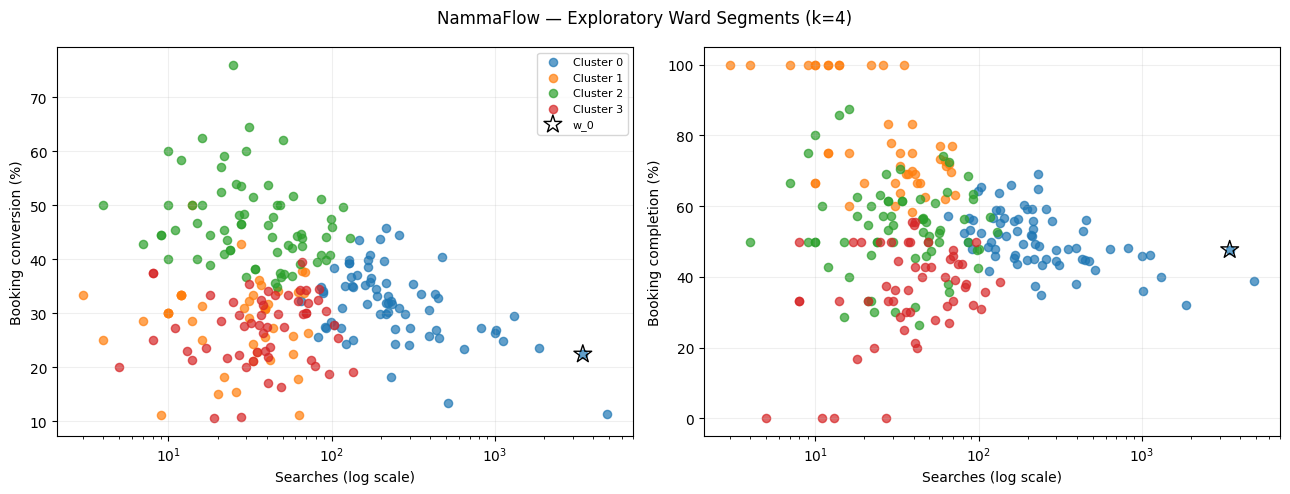

In [ ]:
# 5.5.1 — Visualise the Original Four-Cluster Solution

import matplotlib.pyplot as plt

exploratory_k = 4
exploratory_model = candidate_models[exploratory_k]

cluster_plot_data = clustering_base.copy()
cluster_plot_data["cluster"] = exploratory_model.predict(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_specs = [
    ("ward_search_to_booking_rate", "Booking conversion (%)"),
    ("ward_booking_completion_rate", "Booking completion (%)"),
]

colours = plt.get_cmap("tab10")

for ax, (rate_column, ylabel) in zip(axes, plot_specs):
    for cluster in range(exploratory_k):
        group = cluster_plot_data[
            cluster_plot_data["cluster"].eq(cluster)
        ]

        ax.scatter(
            group["ward_searches"],
            group[rate_column] * 100,
            color=colours(cluster),
            label=f"Cluster {cluster}",
            alpha=0.7,
            s=35,
        )

    special = cluster_plot_data[
        cluster_plot_data["ward_num"].eq("w_0")
    ]

    if not special.empty:
        ax.scatter(
            special["ward_searches"],
            special[rate_column] * 100,
            marker="*",
            s=180,
            facecolors="none",
            edgecolors="black",
            label="w_0",
        )

    ax.set_xscale("log")
    ax.set_xlabel("Searches (log scale)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)

axes[0].legend(fontsize=8)
fig.suptitle("NammaFlow — Exploratory Ward Segments (k=4)")
fig.tight_layout()
plt.show()

**5.5.1 — Cluster Visualisation: Findings**

- The four-cluster solution separates records by a combination of
  search volume, booking conversion, and booking completion.
- Cluster 0 generally captures higher-volume records; clusters 1,
  2, and 3 differ more visibly in their conversion characteristics.
- Groups overlap in both two-dimensional views, consistent with
  the limited silhouette score of approximately 0.30.
- Extreme completion rates occur among some low-volume records
  and should be interpreted alongside booking counts.
- w_0 appears within the higher-volume group.

**Conclusion:** These clusters provide exploratory profiles of the
observed dataset. They are sensitive to population selection and
do not establish causes or justify operational interventions alone.

In [ ]:
# 5.6.1 — Save Exploratory Clustering Checkpoint

from pathlib import Path
import json
import joblib
import sklearn

repo = Path("/content/NammaFlow")
report_dir = repo / "reports/ward_clustering"
model_dir = repo / "models"

report_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "ward_assignments.csv": cluster_plot_data,
    "excluded_records.csv": clustering_excluded,
    "cluster_profiles_k4.csv": candidate_profiles[4],
    "candidate_evaluation.csv": cluster_evaluation,
    "initialization_stability.csv": initialization_stability,
    "w0_sensitivity.csv": w0_sensitivity,
    "subsample_stability.csv": subsample_stability,
    "low_count_sensitivity.csv": low_count_sensitivity,
    "scaling_sensitivity.csv": scaling_sensitivity,
}

for filename, table in tables.items():
    table.to_csv(
        report_dir / filename,
        index=(filename == "cluster_profiles_k4.csv"),
    )

fig.savefig(
    report_dir / "exploratory_clusters_k4.png",
    dpi=160,
    bbox_inches="tight",
)

bundle = {
    "scaler": cluster_scaler,
    "model": exploratory_model,
    "feature_order": list(clustering_features.columns),
    "raw_feature_order": initial_features,
    "search_transform": "numpy.log1p",
    "status": "EXPLORATORY",
}

model_path = model_dir / "nammaflow_ward_clusters_k4_v1.joblib"
joblib.dump(bundle, model_path)

# Verify saved objects reproduce the current assignments.
restored = joblib.load(model_path)

ordered_features = clustering_features[restored["feature_order"]]

restored_scaled = pd.DataFrame(
    restored["scaler"].transform(ordered_features),
    columns=restored["feature_order"],
    index=ordered_features.index,
)

assert np.array_equal(
    restored["model"].predict(restored_scaled),
    cluster_plot_data["cluster"].to_numpy(),
)

metadata = {
    "status": "EXPLORATORY",
    "k": 4,
    "eligible_records": len(clustering_base),
    "excluded_records": len(clustering_excluded),
    "features": list(clustering_features.columns),
    "scikit_learn_version": sklearn.__version__,
    "limitations": [
        "Limited cluster separation",
        "Sensitive to low-booking-record exclusion",
        "Some subsamples change assignments materially",
        "w_0 geographic meaning unresolved",
        "No temporal validation",
        "Driver supply excluded from clustering inputs",
    ],
}

(model_dir / "nammaflow_ward_clusters_k4_v1.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Checkpoint saved:", report_dir)
print("Model saved:", model_path)
print("Reloaded assignments match.")

Checkpoint saved: /content/NammaFlow/reports/ward_clustering
Model saved: /content/NammaFlow/models/nammaflow_ward_clusters_k4_v1.joblib
Reloaded assignments match.


### 5.7 — Alternative Method: Ward Hierarchical Clustering

**Objective:** Compare four-cluster Ward hierarchical clustering with
the existing K-Means solution.

**Method:** Use the same 241 eligible records, three transformed
features, and existing scaling so the comparison changes only the
clustering method.

**Evaluation:** Compare silhouette scores, cluster sizes, and agreement
between methods. Then inspect profiles and low-booking sensitivity.

**Limitation:** Agreement between methods does not establish operational
validity. Cluster numbers are identifiers, not performance rankings.

In [17]:
# 5.7.1 — Compare Ward Hierarchical Clustering with K-Means

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score

assert X_cluster.index.equals(clustering_base.index)
assert len(X_cluster) == 241
assert np.isfinite(X_cluster.to_numpy()).all()

ward_model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward",
)

ward_labels = ward_model.fit_predict(X_cluster)
kmeans_labels = candidate_models[4].predict(X_cluster)

method_comparison = pd.DataFrame({
    "method": ["K-Means", "Ward hierarchical"],
    "records": [len(X_cluster), len(X_cluster)],
    "silhouette": [
        silhouette_score(X_cluster, kmeans_labels),
        silhouette_score(X_cluster, ward_labels),
    ],
})

cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts(),
    "Ward hierarchical": pd.Series(ward_labels).value_counts(),
}).sort_index()

cluster_sizes.index.name = "cluster_id"

print("METHOD COMPARISON")
display(method_comparison.round(4))

print("\nCLUSTER SIZES — IDs do not correspond between methods")
display(cluster_sizes)

print(
    "\nAgreement between methods (ARI):",
    round(adjusted_rand_score(kmeans_labels, ward_labels), 4),
)

METHOD COMPARISON


,method,records,silhouette
0,K-Means,241,0.3000
1,Ward hierarchical,241,0.2588



CLUSTER SIZES — IDs do not correspond between methods


,K-Means,Ward hierarchical
cluster_id,,
0,71,91
1,46,55
2,69,41
3,55,54



Agreement between methods (ARI): 0.5588


**5.7.1 — Method Comparison: Findings**

- Both methods used the same 241 records and scaled features.
- K-Means produced a higher silhouette score (0.3000) than
  Ward hierarchical clustering (0.2588).
- Between-method agreement was ARI=0.5588, indicating partial
  agreement with meaningful differences in membership.
- Cluster IDs do not correspond between methods.

**Next step:** Compare feature profiles and membership overlap.
Neither result establishes operationally reliable ward categories.

In [18]:
# 5.7.2 — Compare Profiles and Membership Overlap

method_profile_data = clustering_base.copy()
method_profile_data["kmeans_cluster"] = kmeans_labels
method_profile_data["ward_cluster"] = ward_labels

for label_column, method_name in [
    ("kmeans_cluster", "K-Means"),
    ("ward_cluster", "Ward hierarchical"),
]:
    profiles = method_profile_data.groupby(label_column).agg(
        records=("ward_num", "size"),
        median_searches=("ward_searches", "median"),
        median_conversion=("ward_search_to_booking_rate", "median"),
        median_completion=("ward_booking_completion_rate", "median"),
    )

    profiles["median_conversion"] *= 100
    profiles["median_completion"] *= 100

    profiles = profiles.rename(columns={
        "median_conversion": "median_conversion_pct",
        "median_completion": "median_completion_pct",
    })

    print(f"\n{method_name.upper()} — CLUSTER PROFILES")
    display(profiles.round(2))

print("\nMEMBERSHIP OVERLAP — COUNTS")
display(pd.crosstab(
    method_profile_data["kmeans_cluster"],
    method_profile_data["ward_cluster"],
    rownames=["K-Means cluster"],
    colnames=["Ward cluster"],
))


K-MEANS — CLUSTER PROFILES


,records,median_searches,median_conversion_pct,median_completion_pct
kmeans_cluster,,,,
0,71,214.0,31.84,49.30
1,46,32.0,30.00,74.17
2,69,33.0,44.62,53.33
3,55,39.0,27.78,37.04



WARD HIERARCHICAL — CLUSTER PROFILES


,records,median_searches,median_conversion_pct,median_completion_pct
ward_cluster,,,,
0,91,46.0,42.86,56.25
1,55,230.0,29.79,48.65
2,41,26.0,28.12,73.33
3,54,41.0,29.68,33.33



MEMBERSHIP OVERLAP — COUNTS


Ward cluster,0,1,2,3
K-Means cluster,,,,
0,16,54,0,1
1,12,1,33,0
2,62,0,0,7
3,1,0,8,46


**5.7.2 — Profile Comparison: Findings**

Both methods identify broadly similar profiles involving higher search
volume, higher conversion, higher completion, and lower completion.

Membership overlap is substantial for these corresponding profiles,
but the methods do not assign every record consistently. Ward cluster 0
combines records from several K-Means groups.

**Interpretation:** Some broad feature patterns persist across methods.
This does not establish stable ward categories or resolve sensitivity
to excluding low-booking records.

In [19]:
# 5.7.3 — Ward Low-Booking Sensitivity

from sklearn.preprocessing import StandardScaler

booking_counts = ward_df.loc[
    clustering_features.index, "ward_bookings"
]
ward_reliable_mask = booking_counts.ge(10)

assert clustering_features.index.equals(X_cluster.index)

ward_reference = ward_labels[ward_reliable_mask.to_numpy()]

# Restricted sample, retaining the original scaling.
ward_fixed_X = X_cluster.loc[ward_reliable_mask]
ward_fixed_labels = AgglomerativeClustering(
    n_clusters=4, linkage="ward"
).fit_predict(ward_fixed_X)

# Restricted sample, refitting the scaling.
ward_refitted_X = StandardScaler().fit_transform(
    clustering_features.loc[ward_reliable_mask]
)
ward_refitted_labels = AgglomerativeClustering(
    n_clusters=4, linkage="ward"
).fit_predict(ward_refitted_X)

ward_low_count_sensitivity = pd.DataFrame([
    {
        "scaling": "Original",
        "retained_records": len(ward_fixed_X),
        "ARI_vs_original_Ward": adjusted_rand_score(
            ward_reference, ward_fixed_labels
        ),
        "silhouette": silhouette_score(
            ward_fixed_X, ward_fixed_labels
        ),
    },
    {
        "scaling": "Refitted",
        "retained_records": len(ward_refitted_X),
        "ARI_vs_original_Ward": adjusted_rand_score(
            ward_reference, ward_refitted_labels
        ),
        "silhouette": silhouette_score(
            ward_refitted_X, ward_refitted_labels
        ),
    },
])

display(ward_low_count_sensitivity.round(4))
print(
    "Excluded below 10 bookings:",
    int((~ward_reliable_mask).sum()),
)

,scaling,retained_records,ARI_vs_original_Ward,silhouette
0,Original,174,0.3474,0.2755
1,Refitted,174,0.1821,0.2453


Excluded below 10 bookings: 67


**5.7.3 — Ward Sensitivity: Findings**

The exploratory threshold of at least 10 bookings retained 174 records
and excluded 67.

Agreement with the original Ward grouping was low:
- Original scaling: ARI=0.3474; silhouette=0.2755.
- Refitted scaling: ARI=0.1821; silhouette=0.2453.

Ward clustering is sensitive to population selection even when the
original scaling is retained. The alternative method does not resolve
the sensitivity previously observed with K-Means.

**Decision:** Retain K-Means k=4 as an exploratory description of the
original eligible dataset. Robust ward segmentation has not been
established. Cluster assignments alone should not drive recommendations.

In [20]:
# 5.8 — Save Alternative-Method Comparison

from pathlib import Path

report_dir = Path("/content/NammaFlow/reports/ward_clustering")
report_dir.mkdir(parents=True, exist_ok=True)

method_comparison.to_csv(
    report_dir / "method_comparison.csv", index=False
)

method_profile_data.to_csv(
    report_dir / "method_comparison_assignments.csv", index=False
)

ward_low_count_sensitivity.to_csv(
    report_dir / "ward_low_count_sensitivity.csv", index=False
)

overlap = pd.crosstab(
    method_profile_data["kmeans_cluster"],
    method_profile_data["ward_cluster"],
    rownames=["kmeans_cluster"],
    colnames=["ward_cluster"],
)
overlap.to_csv(report_dir / "method_membership_overlap.csv")

print("Saved four comparison tables to:", report_dir)

Saved four comparison tables to: /content/NammaFlow/reports/ward_clustering


### 5.9 — Final Clustering Conclusion

**Scope:** This notebook addresses the clustering component of roadmap
Phase 6 — Unsupervised Learning & Anomaly Detection. Anomaly detection
is a separate outstanding component.

**Results:** K-Means and Ward hierarchical clustering were compared
using the same 241 eligible records and three scaled features.
K-Means k=4 had a silhouette of 0.3000 versus 0.2588 for Ward.
Between-method agreement was ARI=0.5588.

Both methods showed broadly similar feature profiles, but substantial
membership changes occurred after excluding records with fewer than
10 bookings. The threshold was an exploratory sensitivity scenario.

**Decision:** Retain K-Means k=4 as an exploratory description of this
dataset. Robust, operationally reliable ward categories have not been
established.

**Limitations:**
- Three records with undefined completion rates were excluded from fitting.
- The geographic meaning of w_0 remains unresolved.
- Demand–supply temporal compatibility remains unverified.
- Clusters do not establish causes or justify interventions.

**Next:** Review the outstanding anomaly-detection scope and
demand–supply intelligence requirements against the project roadmap.

In [21]:
# 5.6.2 — Download Clustering Checkpoint

from pathlib import Path
import zipfile
from google.colab import files

repo = Path("/content/NammaFlow")
zip_path = Path("/content/NammaFlow_clustering_checkpoint.zip")

checkpoint_files = sorted(
    (repo / "reports/ward_clustering").glob("*")
) + [
    repo / "models/nammaflow_ward_clusters_k4_v1.joblib",
    repo / "models/nammaflow_ward_clusters_k4_v1.json",
]

assert checkpoint_files
assert all(path.is_file() for path in checkpoint_files)

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for path in checkpoint_files:
        archive.write(path, arcname=str(path.relative_to(repo)))

print("Packaged files:", len(checkpoint_files))
files.download(str(zip_path))

Packaged files: 17


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>